In [ ]:
import keras
(x_train,y_train),(x_test,y_test) = keras.datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3506s 21us/step


In [31]:
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((50000, 32, 32, 3), (10000, 32, 32, 3), (50000, 1), (10000, 1))

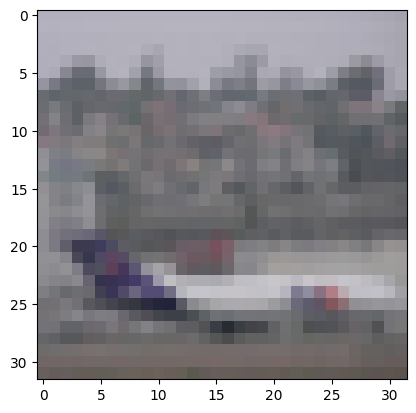

In [ ]:
from matplotlib import pyplot as plt
plt.imshow(x_train[30000])
plt.show()

In [ ]:
y_test[1000]

array([5], dtype=uint8)

##Normalizing features

In [ ]:
import numpy as np
x_train = x_train / 255.0
x_test = x_test / 255.0

##layers building

In [41]:
keras.backend.clear_session()
from keras.models import Sequential
from keras.layers import Flatten, Dense

model = Sequential()
model.add(layer = Flatten(input_shape = (32,32,3), name = "input_Layer"))
model.add(layer = Dense(units = 100, activation= 'elu', name = 'Hidden_Layer_1'))
model.add(layer = Dense(units = 75, activation = 'elu', name = 'Hidden_Layer_2'))
model.add(layer = Dense(units = 10, activation = 'softmax', name ='Output_Layer'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


##Back propogation

In [42]:
model.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

##Training

In [43]:
history = model.fit(x = x_train, y = y_train , batch_size = 775, epochs = 15, validation_data = (x_test, y_test))

Epoch 1/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - accuracy: 0.2048 - loss: 2.1805 - val_accuracy: 0.2868 - val_loss: 2.0199
Epoch 2/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.2993 - loss: 1.9562 - val_accuracy: 0.3179 - val_loss: 1.9145
Epoch 3/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.3229 - loss: 1.9024 - val_accuracy: 0.3236 - val_loss: 1.8873
Epoch 4/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.3392 - loss: 1.8675 - val_accuracy: 0.3438 - val_loss: 1.8484
Epoch 5/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.3527 - loss: 1.8372 - val_accuracy: 0.3557 - val_loss: 1.8221
Epoch 6/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.3585 - loss: 1.8158 - val_accuracy: 0.3653 - val_loss: 1.8038
Epoch 7/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.3648 - loss: 1.7990 - val_accuracy: 0.3697 - val_loss: 1.7877
Epoch 8/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.3699 - loss: 1.7861 - val_accuracy: 0.3806 - v

##plots

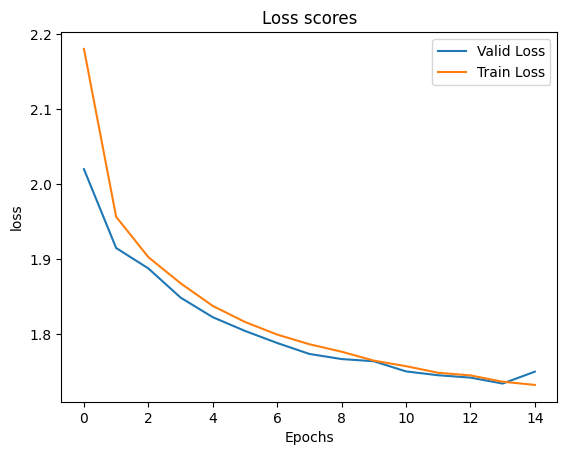

In [49]:
from matplotlib import pyplot as plt
plt.plot(history.history['val_loss'], label = 'Valid Loss')
plt.plot(history.history['loss'], label = 'Train Loss')
plt.title("Loss scores")
plt.xlabel('Epochs')
plt.ylabel('loss')
plt.legend()
plt.show()

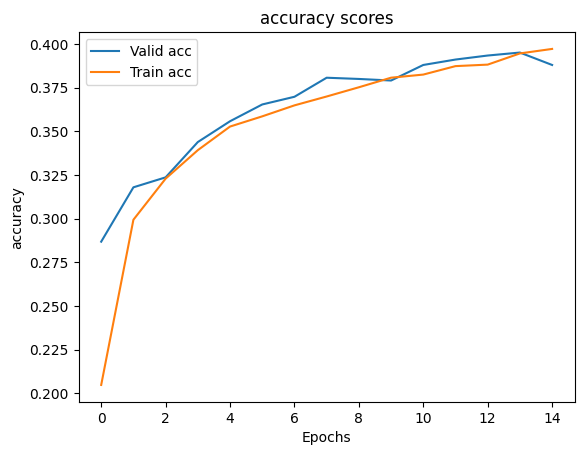

In [47]:
plt.plot(history.history['val_accuracy'], label = 'Valid acc')
plt.plot(history.history['accuracy'], label = 'Train acc')
plt.title("accuracy scores")
plt.xlabel('Epochs')
plt.ylabel('accuracy')
plt.legend()
plt.show()

##External data

In [51]:
model.save('category_intel.h5')

In [71]:
from PIL import Image
img_path = r"/content/frog-2.png"

image = Image.open(img_path).convert('RGB').resize(size= (32,32))
image = np.array(image)
image = image / 255.0
image = np.expand_dims(a = image, axis = 0)
image.shape

(1, 32, 32, 3)

In [72]:
from keras.models import load_model
def pred_image(image):
  cate_brain = load_model('category_intel.h5')
  prediction = cate_brain.predict(image)
  return np.argmax(prediction)

In [73]:
pred_cat = str(pred_image(image))
pred_cat

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step


'8'

##Getting that category name

In [74]:
def get_cat_name(brain_pred_cat):
  categories = {'0': 'airplane',
                  '1': 'automobile',
                  '2': 'bird',
                  '3': 'cat',
                  '4': 'deer',
                  '5': 'dog',
                  '6': 'frog',
                  '7': 'horse',
                  '8': 'ship',
                  '9': 'truck'
                  }
  search_key = pred_cat
  if search_key in categories:
    value = categories[search_key]
    print("Category Name:",value)

  else:
    print("Category Not found!")

get_cat_name(pred_cat)

Category Name: ship
